# Import Libraries

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing
import matplotlib.pyplot as plt
from sklearn import datasets, linear_model

## Loading data sets

In [2]:
df = pd.read_csv("/kaggle/input/datasets/sudeeppattanshetty/tips-data/tips.csv")
df.head(10)

,Bill,Tips
0,16,0
1,23,0
2,13,0
3,90,5
4,56,0
5,27,0
6,94,6
7,52,0
8,7,0
9,22,0


## Visualize the data

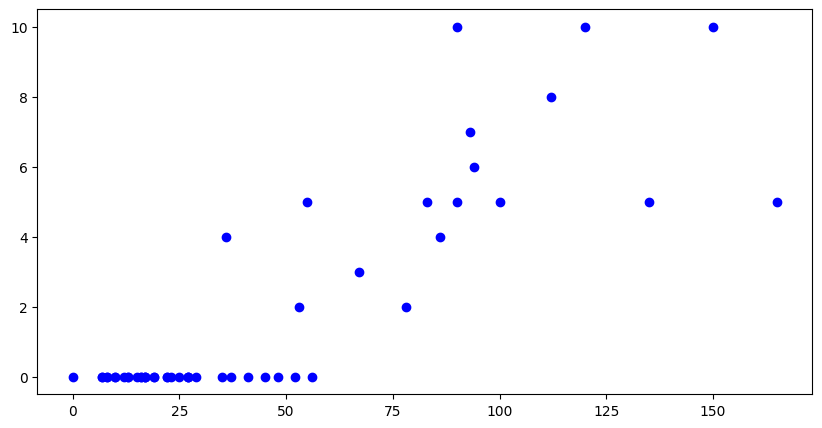

In [3]:
plt.figure(figsize=(10,5))
plt.grid=True
plt.plot(df.Bill, df.Tips, 'o', color='blue')

## Train & Test split

In [4]:
bills = df.Bill
tips = df.Tips

# Trian & Test Split
totalItems = len(bills)
trainRows = int(totalItems*.8) # 80% of total rows

print(f"Total rows:  {totalItems}")
print(f"Train items: {trainRows}")

Total rows:  50
Train items: 40


## Load train data

In [5]:
# Train
bills_train = bills[0:trainRows]
tips_train = tips[0:trainRows]

# # Display Bill and Tips as table columns
# train_data = pd.DataFrame({
#     "Bill": bills_train,
#     "Tips": tips_train
# })

# display(train_data.head())

# bills_train.head()
# print(bills_train)
print(f"Total training rows: {len(bills_train)}")

Total training rows: 40


## Load test data

In [6]:
#Test
bills_test = bills[trainRows:totalItems]
tips_test = tips[trainRows:totalItems]
print(bills_test)
print(f"Total testing rows: {len(bills_test)}")

40     48
41     17
42    135
43     10
44     55
45     36
46     17
47     10
48     29
49     13
Name: Bill, dtype: int64
Total testing rows: 10


## Instantiate LR Model

In [7]:
lin_reg = linear_model.LinearRegression()

## Train

In [8]:
lin_reg.fit(bills_train.to_numpy().reshape(-1, 1), tips_train.to_numpy())

LinearRegression()

## Model Accuracy

In [9]:
result = lin_reg.score(bills_train.to_numpy().reshape(-1, 1), tips_train.to_numpy())
print(f'R sq: {result}')

R sq: 0.7583110841719447


## Predict for test bills

In [10]:
tips_pred = lin_reg.predict(bills_test.to_numpy().reshape(-1, 1))
print(tips_pred)

[ 1.95392199 -0.1361962   7.81973755 -0.60815837  2.42588416  1.14484398
 -0.1361962  -0.60815837  0.67288181 -0.40588887]


## Cross check with actual test data

In [11]:
# Actual 
print(tips_test)

40    0
41    0
42    5
43    0
44    5
45    4
46    0
47    0
48    0
49    0
Name: Tips, dtype: int64


## Infer on random/real time data

In [12]:
print(lin_reg.predict([[100]]))

[5.45992669]


## Coeff

In [13]:
# y = mx = b
print(f"Coeff: {lin_reg.coef_}") #=m

Coeff: [0.06742317]


## Intercept

In [14]:
# y = mx = b
print(f"Intercept: {lin_reg.intercept_}") #=b

Intercept: -1.2823900489218616
